# Unit 5 wiki activity – replicating the K-means animations in code
The two animations (Harris, *Visualizing K-Means Clustering*; and the step-through K-means demo at shabal.in) both show Lloyd's algorithm: **initialise → assign → update → repeat until nothing changes**. This notebook reproduces the "I'll choose" + "Uniform Points" experiment so each animation step can be tied to a line of algorithm logic.

In [1]:
import numpy as np, matplotlib.pyplot as plt
from sklearn.cluster import KMeans
rng = np.random.RandomState(7)
X = rng.uniform(0, 10, size=(200, 2))           # 'Uniform Points': no natural clusters at all

def lloyd(X, centroids, max_iter=50):
    history = []
    for it in range(max_iter):
        d = np.linalg.norm(X[:, None, :] - centroids[None, :, :], axis=2)
        labels = d.argmin(axis=1)                                   # ASSIGN step
        history.append((centroids.copy(), labels.copy(), (d.min(axis=1) ** 2).sum()))
        new_c = np.array([X[labels == k].mean(axis=0) if (labels == k).any() else centroids[k]
                          for k in range(len(centroids))])          # UPDATE step
        if np.allclose(new_c, centroids): break                     # CONVERGENCE test
        centroids = new_c
    return history

def show(history, title, max_panels=6):
    n = min(len(history), max_panels)
    fig, axes = plt.subplots(1, n, figsize=(3.2 * n, 3.2), sharex=True, sharey=True)
    axes = np.atleast_1d(axes)
    for ax, (c, lab, sse) in zip(axes, history[:n]):
        ax.scatter(X[:, 0], X[:, 1], c=lab, cmap='tab10', s=12)
        ax.scatter(c[:, 0], c[:, 1], c='k', marker='X', s=120)
        ax.set_title(f'SSE={sse:.0f}', fontsize=9)
    fig.suptitle(title); plt.tight_layout(); plt.show()

## Run A – the user *chooses* three starting centroids (all placed close together on the left)

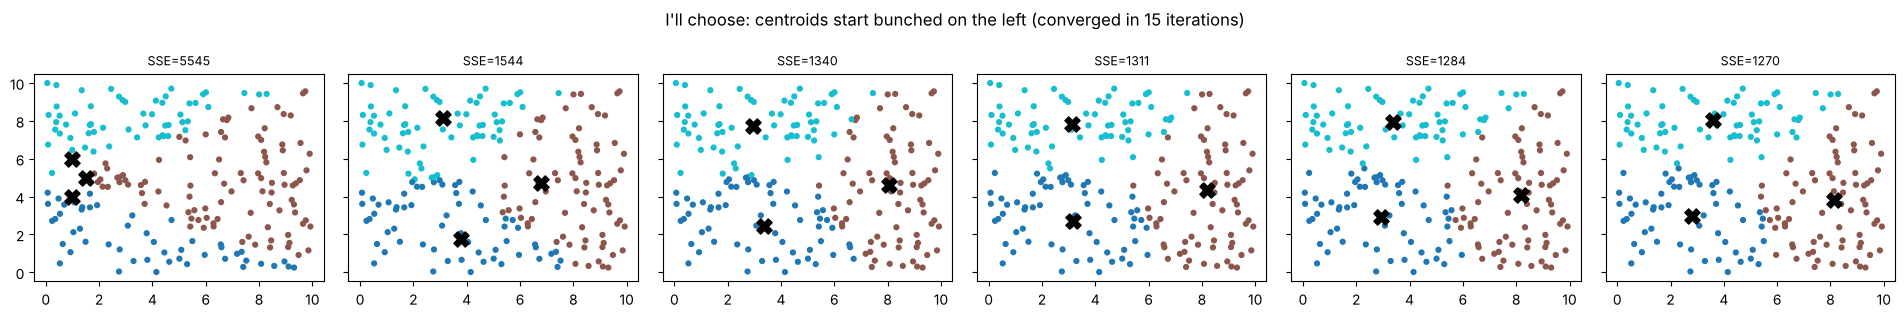

Iterations: 15 | final SSE: 1258.4 | cluster sizes: [55 76 69]


In [2]:
start_A = np.array([[1.0, 4.0], [1.5, 5.0], [1.0, 6.0]])
hist_A = lloyd(X, start_A)
show(hist_A, f"I'll choose: centroids start bunched on the left (converged in {len(hist_A)} iterations)")
print('Iterations:', len(hist_A), '| final SSE:', round(hist_A[-1][2], 1), '| cluster sizes:', np.bincount(hist_A[-1][1]))

## Run B – three well-spread starting centroids on the same data

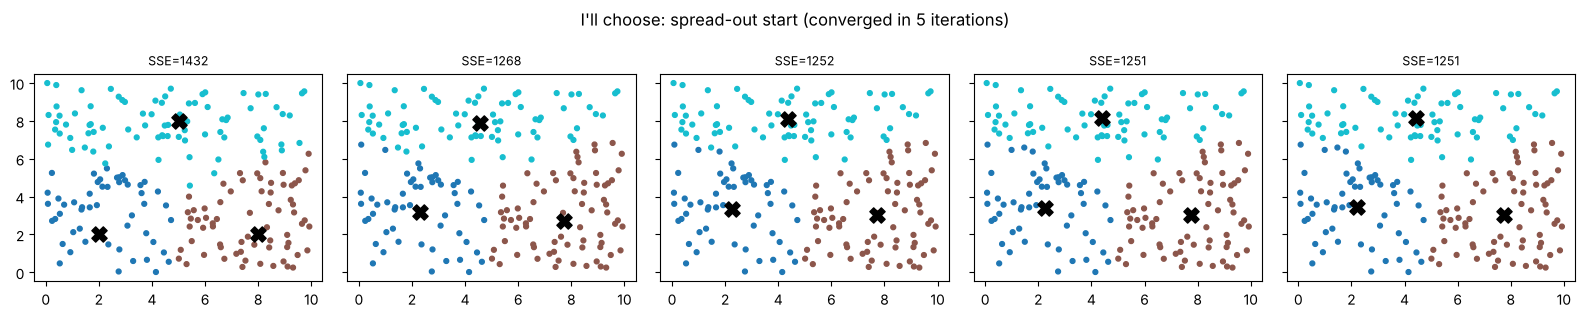

Iterations: 5 | final SSE: 1251.0 | cluster sizes: [56 74 70]
Agreement between the two final partitions (adjusted Rand index, 1 = identical): 0.829


In [3]:
start_B = np.array([[2.0, 2.0], [8.0, 2.0], [5.0, 8.0]])
hist_B = lloyd(X, start_B)
show(hist_B, f"I'll choose: spread-out start (converged in {len(hist_B)} iterations)")
print('Iterations:', len(hist_B), '| final SSE:', round(hist_B[-1][2], 1), '| cluster sizes:', np.bincount(hist_B[-1][1]))
from sklearn.metrics import adjusted_rand_score
print('Agreement between the two final partitions (adjusted Rand index, 1 = identical):',
      round(adjusted_rand_score(hist_A[-1][1], hist_B[-1][1]), 3))

## Does initialisation matter? 200 random starts on the same uniform data

SSE over 200 random starts: min=1210.6, median=1224.8, max=1368.4
k-means++ (n_init=10)     : 1216.6


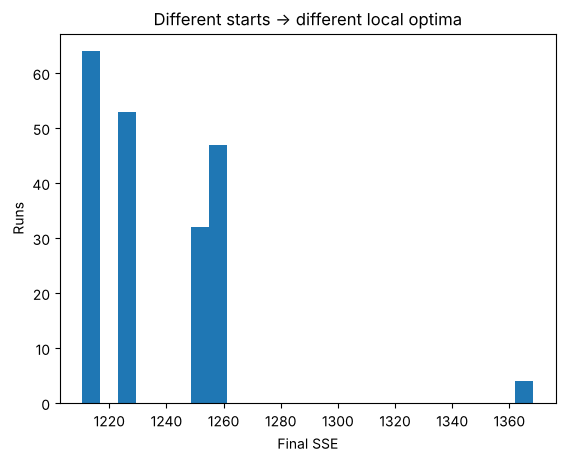

In [4]:
sse = [KMeans(n_clusters=3, init='random', n_init=1, random_state=s).fit(X).inertia_ for s in range(200)]
print(f'SSE over 200 random starts: min={min(sse):.1f}, median={np.median(sse):.1f}, max={max(sse):.1f}')
print(f'k-means++ (n_init=10)     : {KMeans(3, init="k-means++", n_init=10, random_state=0).fit(X).inertia_:.1f}')
plt.hist(sse, bins=25); plt.xlabel('Final SSE'); plt.ylabel('Runs'); plt.title('Different starts -> different local optima'); plt.show()

## Same algorithm, different k: K-means always returns k groups, even when none exist

In [5]:
for k in (2, 3, 4, 6):
    km = KMeans(k, n_init=10, random_state=0).fit(X)
    print(f'k={k}: SSE={km.inertia_:.1f}')

k=2: SSE=1934.0
k=3: SSE=1216.6


k=4: SSE=825.7
k=6: SSE=517.2


## Observations
* Starting with three centroids bunched on the left, K-means needed 15 iterations (final SSE 1258.4). A spread-out start converged in 5 (SSE 1251.0). The two final partitions agree only partly (adjusted Rand index 0.829).
* On uniform data there are no real clusters, yet K-means still returns three tidy regions. Across 200 random starts the SSE ranged from 1210.6 to 1368.4 (median 1224.8): different starts reach different local optima. k-means++ with 10 restarts reached 1216.6.
* SSE always falls as k rises (1934 at k = 2, 825.7 at k = 4, 517.2 at k = 6), so SSE alone cannot choose k.